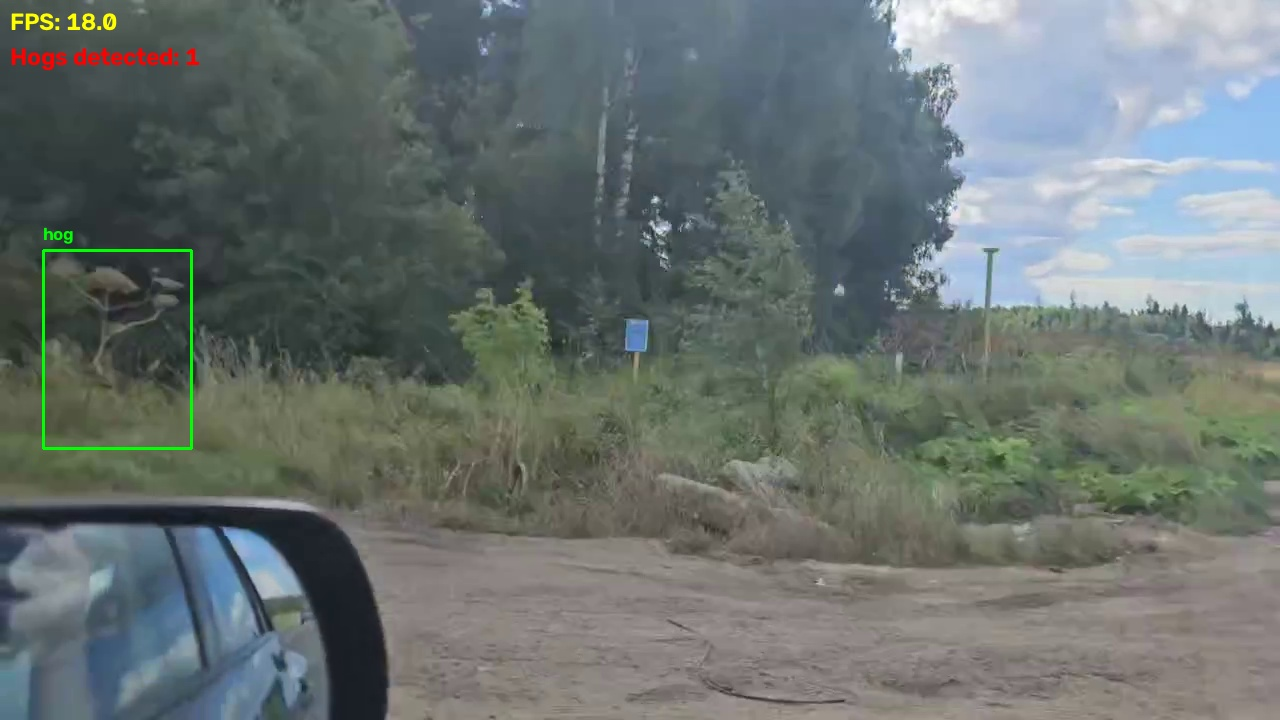

✅ Видеопоток завершен


In [2]:
import cv2
import time
from ultralytics import YOLO
from IPython.display import display, clear_output, Image

# --- НАСТРОЙКИ ---
MODEL_PATH = 'best_733.pt'
VIDEO_INPUT = '19377941908033.mp4'
CONF_THRESHOLD = 0.2

model = YOLO(MODEL_PATH).to('cuda')
cap = cv2.VideoCapture(VIDEO_INPUT)

# Переменные для FPS
prev_time = time.time()

# Создаем "место" для вывода картинки
display_handle = display("", display_id=True)

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    results = model(frame, conf=CONF_THRESHOLD, verbose=False)
    annotated_frame = frame.copy()
    objects_on_frame = 0

    if results[0].boxes is not None:
        for box in results[0].boxes:
            x1, y1, x2, y2 = map(int, box.xyxy[0])
            cls_id = int(box.cls[0])
            class_name = model.names[cls_id]
            objects_on_frame += 1
            cv2.rectangle(annotated_frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
            cv2.putText(annotated_frame, class_name, (x1, y1 - 10),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

    # HUD: FPS и счетчик
    curr_time = time.time()
    fps_display = 1 / (curr_time - prev_time + 1e-6)
    prev_time = curr_time
    cv2.putText(annotated_frame, f"FPS: {fps_display:.1f}", (10, 30),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2)
    cv2.putText(annotated_frame, f"Hogs detected: {objects_on_frame}", (10, 65),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)

    # --- ГЛАВНОЕ: конвертируем кадр в картинку для ноутбука ---
    _, buffer = cv2.imencode('.jpg', annotated_frame)
    # Обновляем картинку в ячейке
    display_handle.update(Image(data=buffer.tobytes()))

cap.release()
print("✅ Видеопоток завершен")